# Step 4: FinOps Rightsizing, Snapshot Remediation & ROI Action Matrix
**Abhi Cloud Tech — Enterprise FinOps & Multi-Cloud Optimization Platform**  
*Lead Architect: Abhishek*

---

### Executive Overview & Industry Realities
Cloud waste is not merely about turning off unused VMs. In real-world enterprise infrastructure, the most persistent waste stems from:
1. **Stale Machine Images & Unattached Disk Snapshots**:
   - AWS EBS Snapshots retained months after parent EC2 instance termination.
   - Azure Managed Disk Snapshots and orphaned Compute Gallery images.
   - GCP Persistent Disk Snapshots and obsolete Custom Machine Images.
   - *Industry standard remediation*: AWS Data Lifecycle Manager (DLM), Azure Backup lifecycle policies, GCP Snapshot Schedules with 30-day retention.
2. **Machine Family Inefficiencies (GCP e2 vs n2, AWS Graviton)**:
   - General workloads assigned to premium `n2-standard-4` ($0.194/hr) instead of cost-optimized `e2-standard-4` ($0.134/hr) - 31% savings.
   - Intel EC2 `m6i.xlarge` instances migrating to AWS Graviton `m6g.xlarge` - 20% savings.
   - Azure `Standard_D4s_v5` migrating to burstable `Standard_B2ms` for non-sustained loads.
3. **Commitment Discounts**: 1-Year/3-Year Savings Plans and Reserved Instances for steady-state baseline compute.


### Block 1: Imports & Database Telemetry Loading


In [1]:
import os
import sys
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))

from src.database import load_focus_dataframe
df = load_focus_dataframe()
df["Date"] = pd.to_datetime(df["Date"])
print(f"Loaded {len(df):,} records for Optimization & Rightsizing Analysis.")
sns.set_theme(style="whitegrid")
%matplotlib inline


Loaded 32,850 records for Optimization & Rightsizing Analysis.


### Block 2: Generate Enterprise Savings Portfolio
We calculate the annualized run rate and breakdown of savings across Idle cleanup, Compute Rightsizing, Commitment Discounts, and Snapshot/Machine Image Cleanup.


In [2]:
from src.optimizer import FinOpsOptimizer

optimizer = FinOpsOptimizer(df)
portfolio = optimizer.generate_savings_portfolio()

print("=" * 60)
print(f"ANNUAL RUN-RATE:            ${portfolio['Annual_Run_Rate_USD']:,.2f}")
print(f"TOTAL ANNUAL SAVINGS:       ${portfolio['Total_Annual_Savings_USD']:,.2f} ({portfolio['Savings_Percentage']}%)")
print(f"FINOPS MATURITY STAGE:      {portfolio['FinOps_Maturity_Stage']} (Score: {portfolio['FinOps_Maturity_Score']}/100)")
print("=" * 60)
print(f" * Snapshot & Image Cleanup: ${portfolio['Snapshot_Cleanup_Savings_USD']:,.2f}/yr")
print(f" * Compute Right-Sizing:     ${portfolio['Right_Sizing_Savings_USD']:,.2f}/yr")
print(f" * Commitment Discounts:     ${portfolio['Commitment_Discounts_Savings_USD']:,.2f}/yr")
print(f" * Idle / Zombie Cleanup:    ${portfolio['Idle_Cleanup_Savings_USD']:,.2f}/yr")
print("=" * 60)


ANNUAL RUN-RATE:            $7,525,028.96
TOTAL ANNUAL SAVINGS:       $2,440,361.56 (32.4%)
FINOPS MATURITY STAGE:      Walk (Proactive / Developing Governance) (Score: 68/100)
 * Snapshot & Image Cleanup: $567,209.59/yr
 * Compute Right-Sizing:     $537,864.92/yr
 * Commitment Discounts:     $1,052,601.32/yr
 * Idle / Zombie Cleanup:    $105,754.26/yr


### Block 3: Prioritized Engineering Action Matrix
The Action Matrix enforces strict prioritization:
- **P1 - Critical**: Stale Machine Images and Disk Snapshots older than 30 days.
- **P2 - High**: Zombie instances with <15% CPU utilization.
- **P3 - Medium**: Compute Rightsizing (GCP e2 vs n2, AWS Graviton m6g, Azure B-series).
- **P4 - Low**: 1-Year / 3-Year Compute Savings Plans & RIs.


In [3]:
action_matrix = optimizer.get_actionable_recommendations_table()
print(f"Total Actionable Recommendations: {len(action_matrix)}")
print("\nAction Matrix by Priority Tier:")
print(action_matrix['Priority'].value_counts())
action_matrix[['Priority', 'Cloud_Provider', 'Resource_Service', 'Issue_Identified', 'Action_Required', 'Est_Monthly_Savings_USD', 'Implementation_Effort']].head(8)


Total Actionable Recommendations: 87

Action Matrix by Priority Tier:
Priority
P2 - High        68
P1 - Critical    17
P3 - Medium       2
Name: count, dtype: int64


,Priority,Cloud_Provider,Resource_Service,Issue_Identified,Action_Required,Est_Monthly_Savings_USD,Implementation_Effort
0,P1 - Critical,AWS,AmazonEC2-Snapshots (Storage),Severely underutilized (0.1% CPU),Downsize instance size or schedule weekend aut...,4288.02,Low (1-2 Hours)
1,P1 - Critical,GCP,Compute Engine - Snapshots & Images (Storage),Severely underutilized (1.2% CPU),Downsize instance size or schedule weekend aut...,4026.83,Low (1-2 Hours)
2,P1 - Critical,Azure,Microsoft.Compute/snapshots (Storage),Severely underutilized (1.2% CPU),Downsize instance size or schedule weekend aut...,3784.94,Low (1-2 Hours)
3,P1 - Critical,AWS,AmazonEC2-Snapshots (Storage),Severely underutilized (0.9% CPU),Downsize instance size or schedule weekend aut...,3263.37,Low (1-2 Hours)
4,P1 - Critical,Azure,Microsoft.Compute/snapshots (Storage),Severely underutilized (0.4% CPU),Downsize instance size or schedule weekend aut...,3181.86,Low (1-2 Hours)
5,P1 - Critical,GCP,Compute Engine - Snapshots & Images (Storage),Severely underutilized (1.0% CPU),Downsize instance size or schedule weekend aut...,2948.88,Low (1-2 Hours)
6,P1 - Critical,AWS,AmazonEC2-Snapshots (Storage),Severely underutilized (1.1% CPU),Downsize instance size or schedule weekend aut...,2837.18,Low (1-2 Hours)
7,P1 - Critical,AWS,AmazonCloudFront (Network),Severely underutilized (23.6% CPU),Downsize instance size or schedule weekend aut...,2571.86,Low (1-2 Hours)


### Block 4: Multi-Cloud Infrastructure as Code (IaC) Remediation Scripts
For each cloud provider, we formulate the exact CLI command to enforce snapshot lifecycle policies:


In [4]:
print("=== MULTI-CLOUD REMEDIATION CLI COMMANDS ===")
print("""
[AWS DLM Snapshot Lifecycle Policy]
aws dlm create-default-role --resource-type snapshot
aws dlm create-lifecycle-policy \
    --description "Automated 30-Day EBS Snapshot Retention" \
    --state ENABLED \
    --execution-role-arn arn:aws:iam::123456789012:role/AWSDataLifecycleManagerDefaultRole \
    --policy-details file://aws_dlm_policy.json

[Azure Backup Retention Policy]
az backup policy create \
    --resource-group rg-production-finops \
    --vault-name rsv-finops-backup \
    --name DailySnapshotRetention30Days \
    --backup-management-type AzureIaasVM \
    --policy policy_azure.json

[Google Cloud Snapshot Schedule]
gcloud compute resource-policies create snapshot-schedule finops-30day-snapshot-retention \
    --region=us-central1 \
    --max-retention-days=30 \
    --daily-schedule \
    --start-time=02:00
""")


=== MULTI-CLOUD REMEDIATION CLI COMMANDS ===

[AWS DLM Snapshot Lifecycle Policy]
aws dlm create-default-role --resource-type snapshot
aws dlm create-lifecycle-policy     --description "Automated 30-Day EBS Snapshot Retention"     --state ENABLED     --execution-role-arn arn:aws:iam::123456789012:role/AWSDataLifecycleManagerDefaultRole     --policy-details file://aws_dlm_policy.json

[Azure Backup Retention Policy]
az backup policy create     --resource-group rg-production-finops     --vault-name rsv-finops-backup     --name DailySnapshotRetention30Days     --backup-management-type AzureIaasVM     --policy policy_azure.json

[Google Cloud Snapshot Schedule]
gcloud compute resource-policies create snapshot-schedule finops-30day-snapshot-retention     --region=us-central1     --max-retention-days=30     --daily-schedule     --start-time=02:00



### Block 5: Executive ROI Waterfall & Provider Savings Visualizations


C:\Users\M Abhishek Reddy\AppData\Local\Temp\ipykernel_4828\1712878025.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=priority_savings, x='Priority', y='Est_Monthly_Savings_USD', palette='viridis')


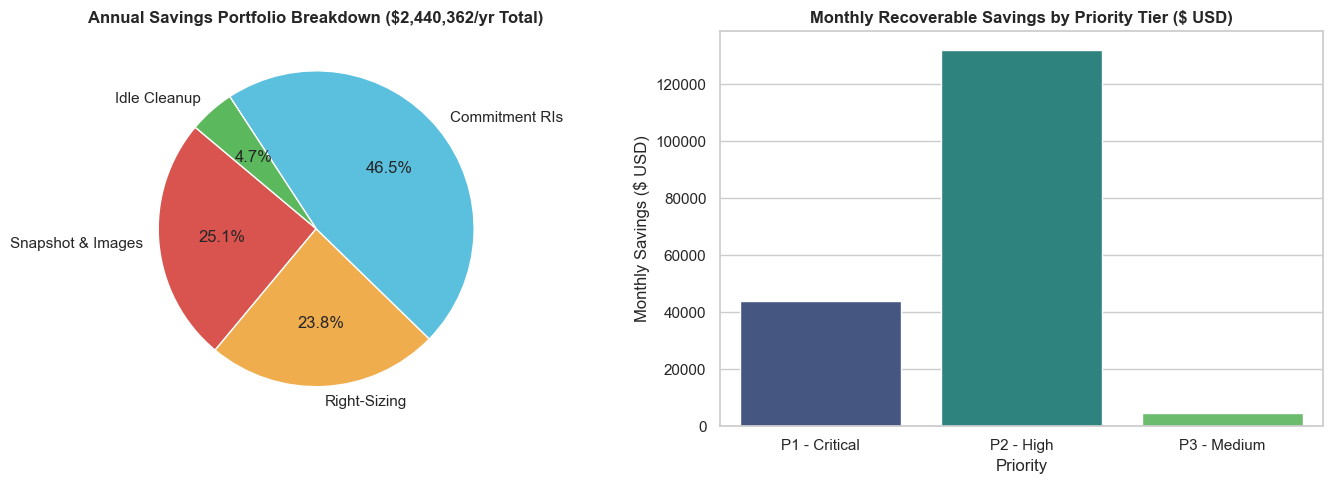

In [5]:
plt.figure(figsize=(14, 5))

# Savings Breakdown Pie
plt.subplot(1, 2, 1)
categories = ['Snapshot & Images', 'Right-Sizing', 'Commitment RIs', 'Idle Cleanup']
savings_values = [
    portfolio['Snapshot_Cleanup_Savings_USD'],
    portfolio['Right_Sizing_Savings_USD'],
    portfolio['Commitment_Discounts_Savings_USD'],
    portfolio['Idle_Cleanup_Savings_USD']
]
colors = ['#d9534f', '#f0ad4e', '#5bc0de', '#5cb85c']
plt.pie(savings_values, labels=categories, autopct='%1.1f%%', colors=colors, startangle=140)
plt.title(f"Annual Savings Portfolio Breakdown (${portfolio['Total_Annual_Savings_USD']:,.0f}/yr Total)", fontsize=12, fontweight='bold')

# Action Matrix Savings by Priority
plt.subplot(1, 2, 2)
priority_savings = action_matrix.groupby('Priority')['Est_Monthly_Savings_USD'].sum().reset_index()
sns.barplot(data=priority_savings, x='Priority', y='Est_Monthly_Savings_USD', palette='viridis')
plt.title("Monthly Recoverable Savings by Priority Tier ($ USD)", fontsize=12, fontweight='bold')
plt.ylabel("Monthly Savings ($ USD)")

plt.tight_layout()
plt.show()
